# Example 6 — Coincidences and timing jitter

For every frame in which both pixels of a pair hold a timestamp, `t_b − t_a` is
one entry of the delta-t histogram. Correlated photons, such as SPDC signal and
idler, pile up in a peak at zero. The fit gives that peak's width, which is the
combined timing jitter of the two detectors.

Full explanation: [Coincidences](../docs/guide/coincidences.md) and
[Background subtraction](../docs/guide/background_subtraction.md).

## What you need

- a timestamping run (`ORT`, or `S0T`...`S3T`) that passed
  [data quality](01_data_quality.ipynb). A TDC that never stopped still gives a
  peak-shaped histogram here, just a meaningless one.
- `nframes`, the frames per file you acquired with.
- two groups of pixels, typically the signal and idler blobs read off the
  [hitmap](05_hitmap.ipynb).
- for calibrated timing, the board's daughterboard and motherboard ids, with
  its tables packaged (see [TDC calibration](02_tdc_calibration.ipynb)).

There is no clock or full-scale argument. The TDC full scale is measured from
the largest code in the run.

## 1. Point dapkel at the data

In [1]:
from dapkel.functions import coincidences as co

path = r"D:\Kelpie\2026.10.30"
nframes = 10_000
tag = "ORT"

signal = [(r, c) for r in range(5, 7) for c in range(11, 13)]
idler = [(r, c) for r in range(18, 21) for c in range(20, 23)]

## 2. Histogram the differences

`process_coincidences` decodes each file once and bins every pixel pair's
differences onto a fine grid as it goes. It saves only the counts, as
`processed/<folder>_ort_coincidences.npy` with one row per pair, so the file
size is set by the grid and not by the length of the run.

The pairing mode decides which pairs are made:

- `mode="all_pairs"` (the default): every signal × idler combination, here
  4 × 9 = 36 pairs;
- `mode="1v1"`: zips the two groups element by element.

`subtract_background=True` also histograms frame-shifted pairs, by default lags
1–8. A real SPDC pair always lands in one frame, so a shifted pair can only be
accidental. Those shifted histograms measure the accidental background directly,
instead of fitting it.

In [4]:
co.process_coincidences(
    path,
    nframes,
    rewrite=True,
    pixels=[signal, idler],
    tag=tag,
    daughterboard_number="D0",
    motherboard_number="M0",
    subtract_background=True,
)
# no packaged calibration for the board: apply_TDC_calibration=False (nominal 71.58 ps/code)
# a quick look on part of the run: max_files=20


!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
!!  rewrite=True - the following data WILL BE OVERWRITTEN:
!!    D:\Kelpie\2026.10.30\processed\2026.10.30_ort_coincidences.npy  (82.3 MB, written 2026-10-31 21:19)
!!  Press Ctrl-C within 5 s to abort and copy it somewhere safe.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
  overwriting in 5 s ...   overwriting in 4 s ...   overwriting in 3 s ...   overwriting in 2 s ...   overwriting in 1 s ... 
  overwriting now.


> > > Histogramming delta-t from 10 'ORT' file(s) onto 9x36x33289 cells of 7.16 ps spanning +/-119.1 ns (82 MB), lags [0, 1, 2, 3, 4, 5, 6, 7, 8] < < <



ORT: 100%|██████████| 10/10 [00:08<00:00,  1.24it/s]


> > > 3643802 difference(s) across 36 pair(s) binned; 0 outside +/-119.1 ns. Saved to D:\Kelpie\2026.10.30\processed\2026.10.30_ort_coincidences.npy < < <
  lag 0: 412852; shifted lags: 403869 on average -> a raw excess of 8983.


'D:\\Kelpie\\2026.10.30\\processed\\2026.10.30_ort_coincidences.npy'

The run writes a checkpoint every 50 files. If it dies, calling it again with
the same inputs resumes where it stopped.

If a complete result for this data set already exists, the call raises
`FileExistsError` rather than overwriting. Pass `rewrite=True` to replace it:
it counts down 5 s, naming the file, so you have time to press Ctrl-C.

## 3. Fit the peak on the raw histogram

`plot_coincidences` reads the saved grid, rebins it in memory, fits the peak and
saves `results/coincidences/<folder>_ort_spdc_coincidences.png`.

On the raw histogram, the accidental background is a **triangle**, not a flat
line, so the model is a Gaussian on a triangle. The free-running oscillator has
no cycle counter, so two independent timestamps difference into a triangle
spanning ± one full scale.

  snapped to the 7.16 ps grid: bin_width 71.58 -> 78.74 ps (11 cells); window 99281 -> 99289 ps.

> > > 412852 difference(s) across 36 pair(s); 412772 inside +/-99.29 ns, rebinned to 2523 x 79 ps < < <

> > > Plot is saved as 2026.10.30_ort_spdc_coincidences.png in D:\Kelpie\2026.10.30\results\coincidences < < <
  peak: mu 167 ps  FWHM 1681 +- 13 ps  sigma 714 +- 6 ps  sigma_detector 505 +- 4 ps  peak/bkg 3.10
sigma 714 ± 6 ps, FWHM 1681 ps, CAR 3.10, ok=True


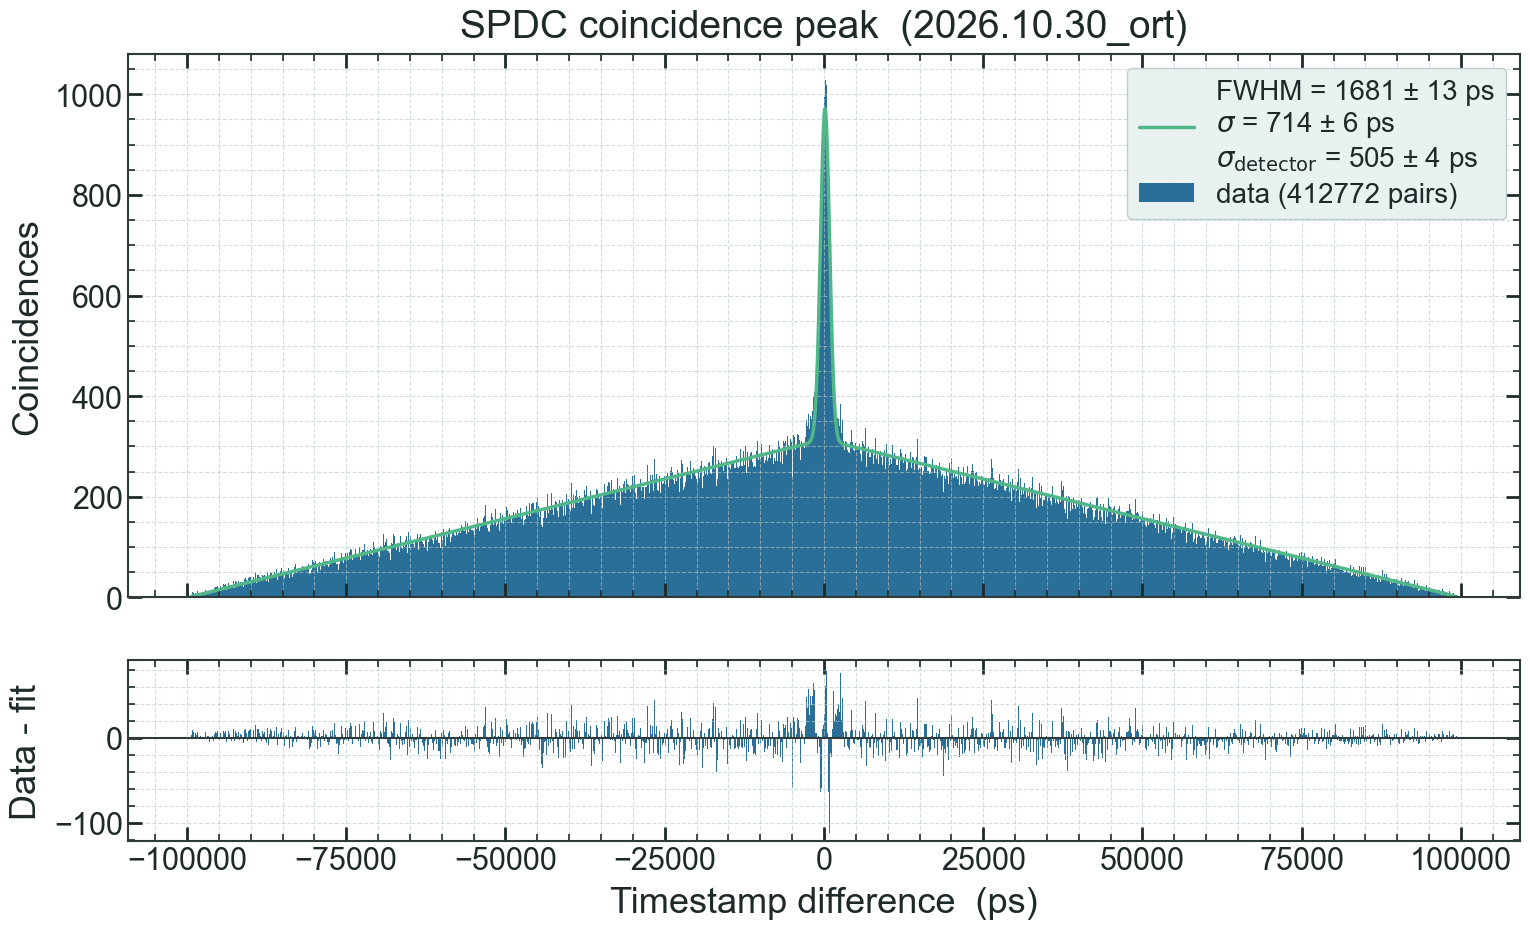

In [5]:
counts, centers, fit = co.plot_coincidences(path, tag)
print(
    f"sigma {fit['sigma']:.0f} ± {fit['sigma_err']:.0f} ps, "
    f"FWHM {fit['fwhm']:.0f} ps, CAR {fit['car']:.2f}, ok={fit['ok']}"
)

`centers` are in picoseconds. Every argument ending in `_s` is in seconds.

## 4. Subtract the accidentals instead

With the lag planes from step 2, the accidentals are removed bin by bin, leaving
the peak on a zero baseline. The fit is then a Gaussian on that zero baseline,
within `fit_window_s` (default 5 ns) of the tallest bin.

  snapped to the 7.16 ps grid: bin_width 71.58 -> 78.74 ps (11 cells); window 20000 -> 19999 ps.

> > > lag 0 412852 vs accidentals 404051 (mean of 8 shifted lag(s)) over the whole support < < <
  coincidences within +/-5000 ps: 16200 +/- 245  (66.0 sigma), on 39128 accidentals -> CAR 0.414
  control, |delta| beyond the peak: -4608 +/- 504 (-9.1 sigma from zero) - this must be ~0, or the pedestal is not purely accidental.

> > > Plot is saved as 2026.10.30_ort_spdc_background_subtraction.png in D:\Kelpie\2026.10.30\results\coincidences < < <

> > > Plot is saved as 2026.10.30_ort_spdc_coincidences_sub.png in D:\Kelpie\2026.10.30\results\coincidences < < <
  peak: mu 165 ps  FWHM 1671 +- 32 ps  sigma 710 +- 14 ps  sigma_detector 502 +- 10 ps
coincidences 16200 ± 245 (66.0 σ), CAR 0.414 within ±5 ns
sigma 710 ± 14 ps, per detector 502 ps


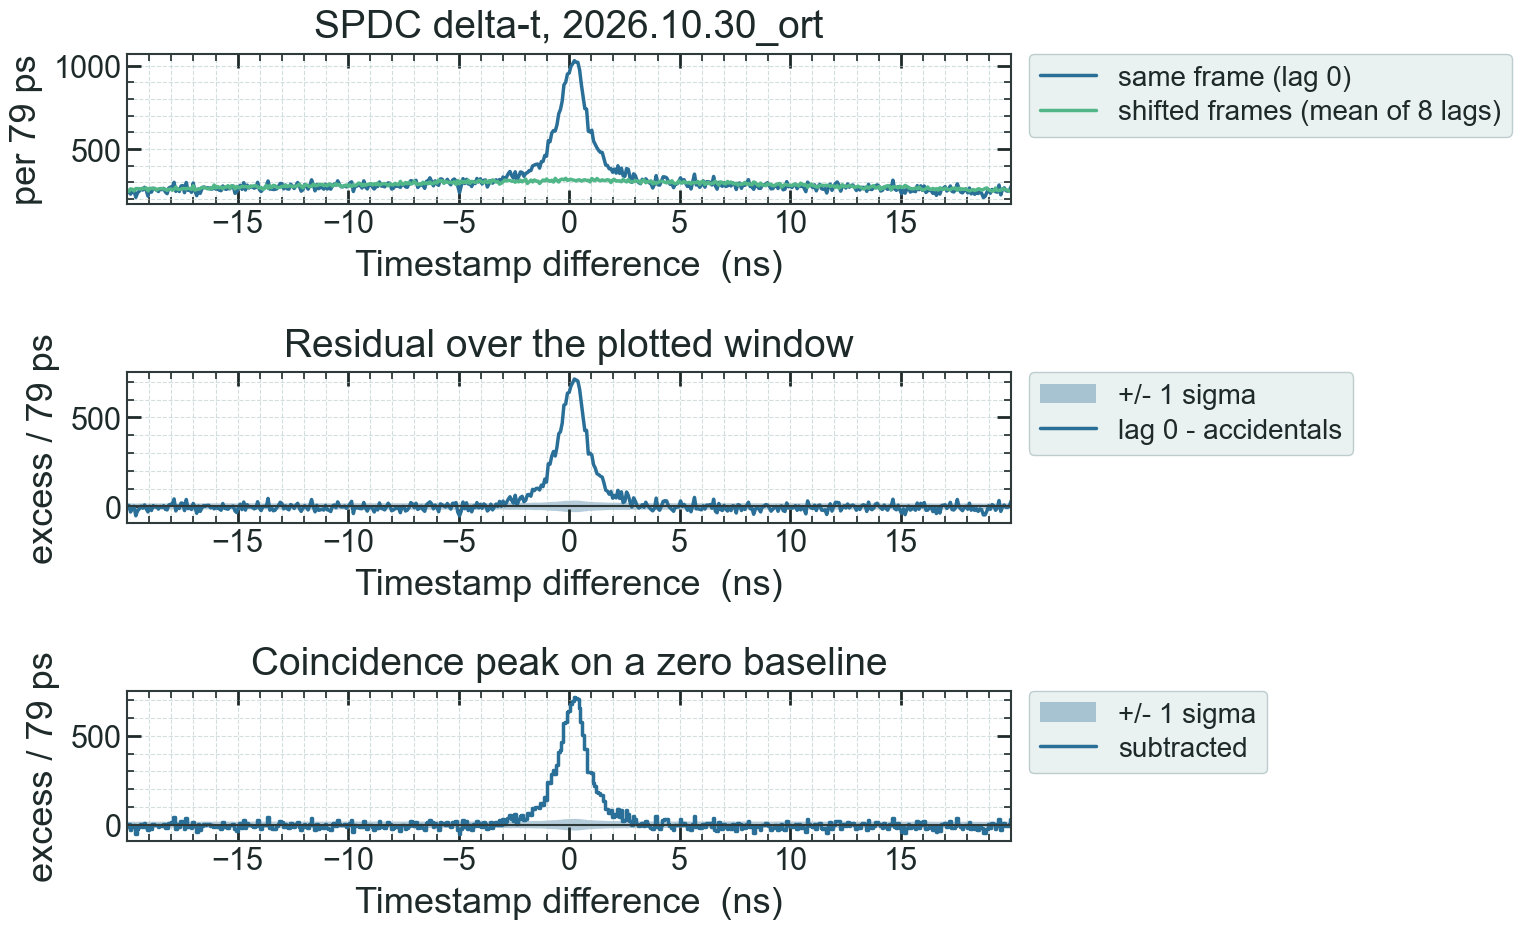

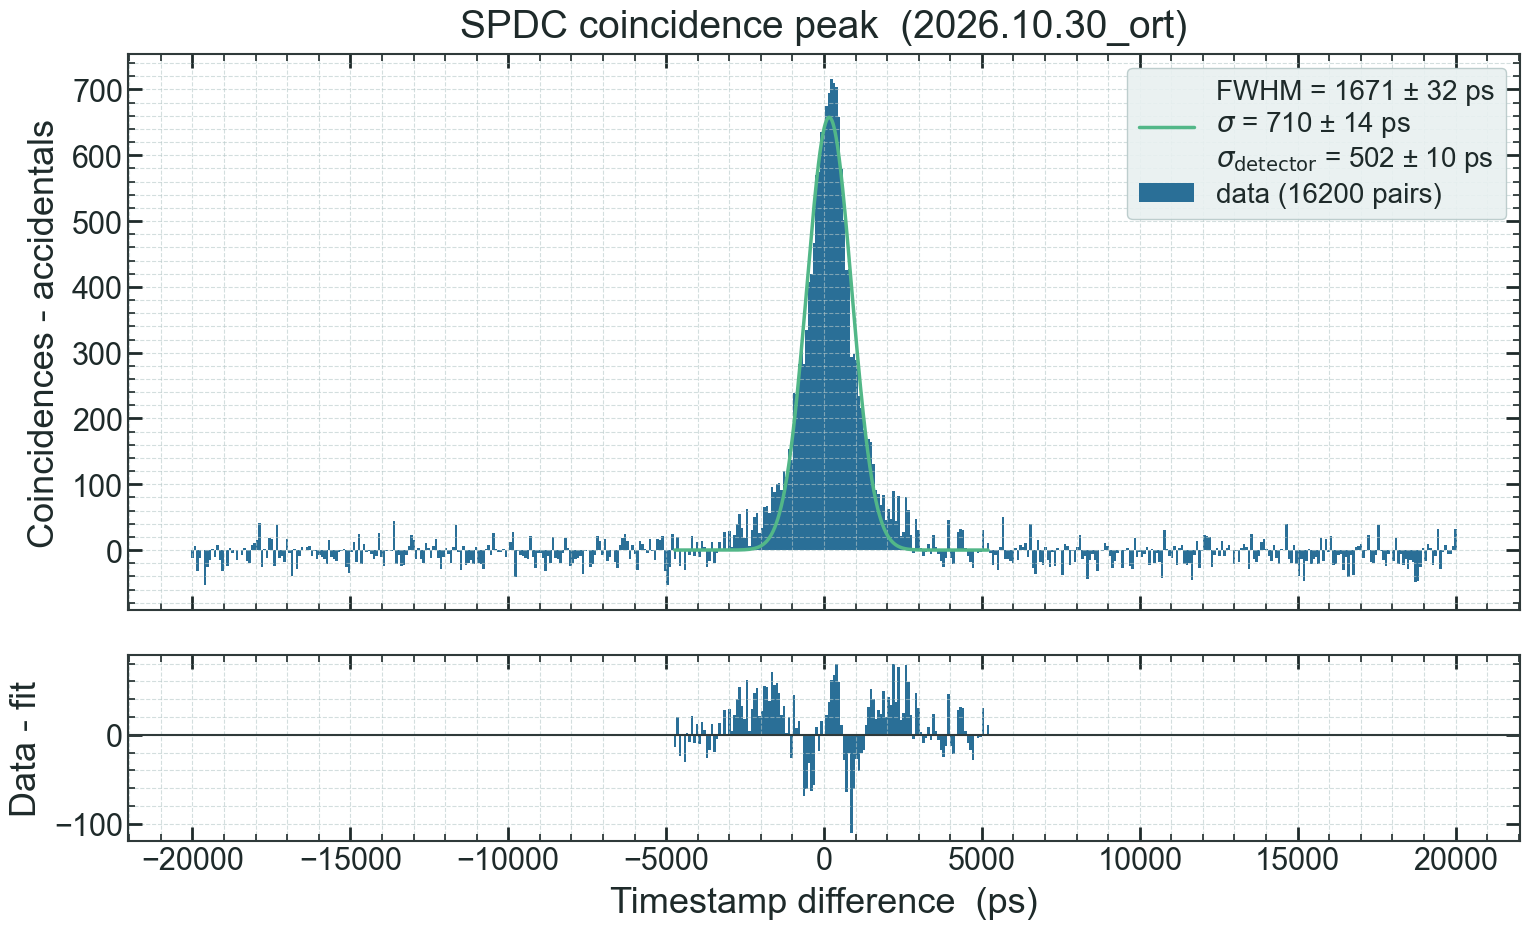

In [6]:
counts, centers, fit = co.plot_coincidences(
    path, tag, subtract_background=True, plot_window_s=20e-9
)

mf = fit["model_free"]
print(
    f"coincidences {mf['n']:.0f} ± {mf['n_err']:.0f} ({mf['significance']:.1f} σ), "
    f"CAR {mf['car']:.3f} within ±{mf['window_s'] * 1e9:.0f} ns"
)
print(
    f"sigma {fit['sigma']:.0f} ± {fit['sigma_err']:.0f} ps, "
    f"per detector {fit['jitter_per_detector']:.0f} ps"
)

Before quoting a number, open `<folder>_ort_spdc_background_subtraction.png`
in the same folder. Its middle panel must be flat and centred on zero far from
the peak. The printout gives the same check as a number, the "control" beyond
the peak, which must be about 0. A run whose rate drifted over time
over-subtracts, and the control comes out several σ negative.

## 5. Rebin, zoom, pick pairs — all free

Nothing below re-reads the raw files.

  snapped to the 7.16 ps grid: bin_width 150.00 -> 150.32 ps (21 cells); window 10000 -> 10071 ps.

> > > lag 0 412852 vs accidentals 404051 (mean of 8 shifted lag(s)) over the whole support < < <
  coincidences within +/-5000 ps: 16212 +/- 246  (65.9 sigma), on 39393 accidentals -> CAR 0.412
  control, |delta| beyond the peak: -4599 +/- 506 (-9.1 sigma from zero) - this must be ~0, or the pedestal is not purely accidental.

> > > Plot is saved as 2026.10.30_ort_spdc_background_subtraction.png in D:\Kelpie\2026.10.30\results\coincidences < < <

> > > Plot is saved as 2026.10.30_ort_spdc_coincidences_sub.png in D:\Kelpie\2026.10.30\results\coincidences < < <
  peak: mu 166 ps  FWHM 1674 +- 42 ps  sigma 711 +- 18 ps  sigma_detector 503 +- 13 ps
['5,11-18,20', '5,11-18,21', '5,11-18,22', '5,11-19,20', '5,11-19,21']
  snapped to the 7.16 ps grid: bin_width 71.58 -> 78.74 ps (11 cells); window 99281 -> 99289 ps.

> > > lag 0 16077 vs accidentals 15315 (mean of 8 shifted lag(s)) over the who

(array([-0.12505002,  0.        , -0.12510008, ..., -0.12508756,
        -0.1250125 , -0.12508756], shape=(2523,)),
 array([-99288.618, -99209.88 , -99131.142, ...,  99131.142,  99209.88 ,
         99288.618], shape=(2523,)),
 {'amp': 17.214775219476756,
  'mu': 233.792028824678,
  'sigma': 1012.2278533768789,
  'sigma_err': 87.4261807452532,
  'bkg': 0.0,
  'fwhm': 2383.79659470255,
  'fwhm_err': 205.8886556550713,
  'jitter_per_detector': np.float64(715.7531792286934),
  'jitter_per_detector_err': np.float64(61.819645258209306),
  'ok': True,
  'fit_range': (-4724.28, 5196.708),
  'car': nan,
  'n': 593,
  'model_free': {'n': 593.4686655423766,
   'n_err': 47.26942463304029,
   'significance': 12.555021986190097,
   'n_background': 1458.5313344576232,
   'car': 0.40689469709820586,
   'window_s': 5e-09,
   'n_bins': 127},
  'subtraction': {'centers': array([-99288.618, -99209.88 , -99131.142, ...,  99131.142,  99209.88 ,
           99288.618], shape=(2523,)),
   'signal': array([0., 

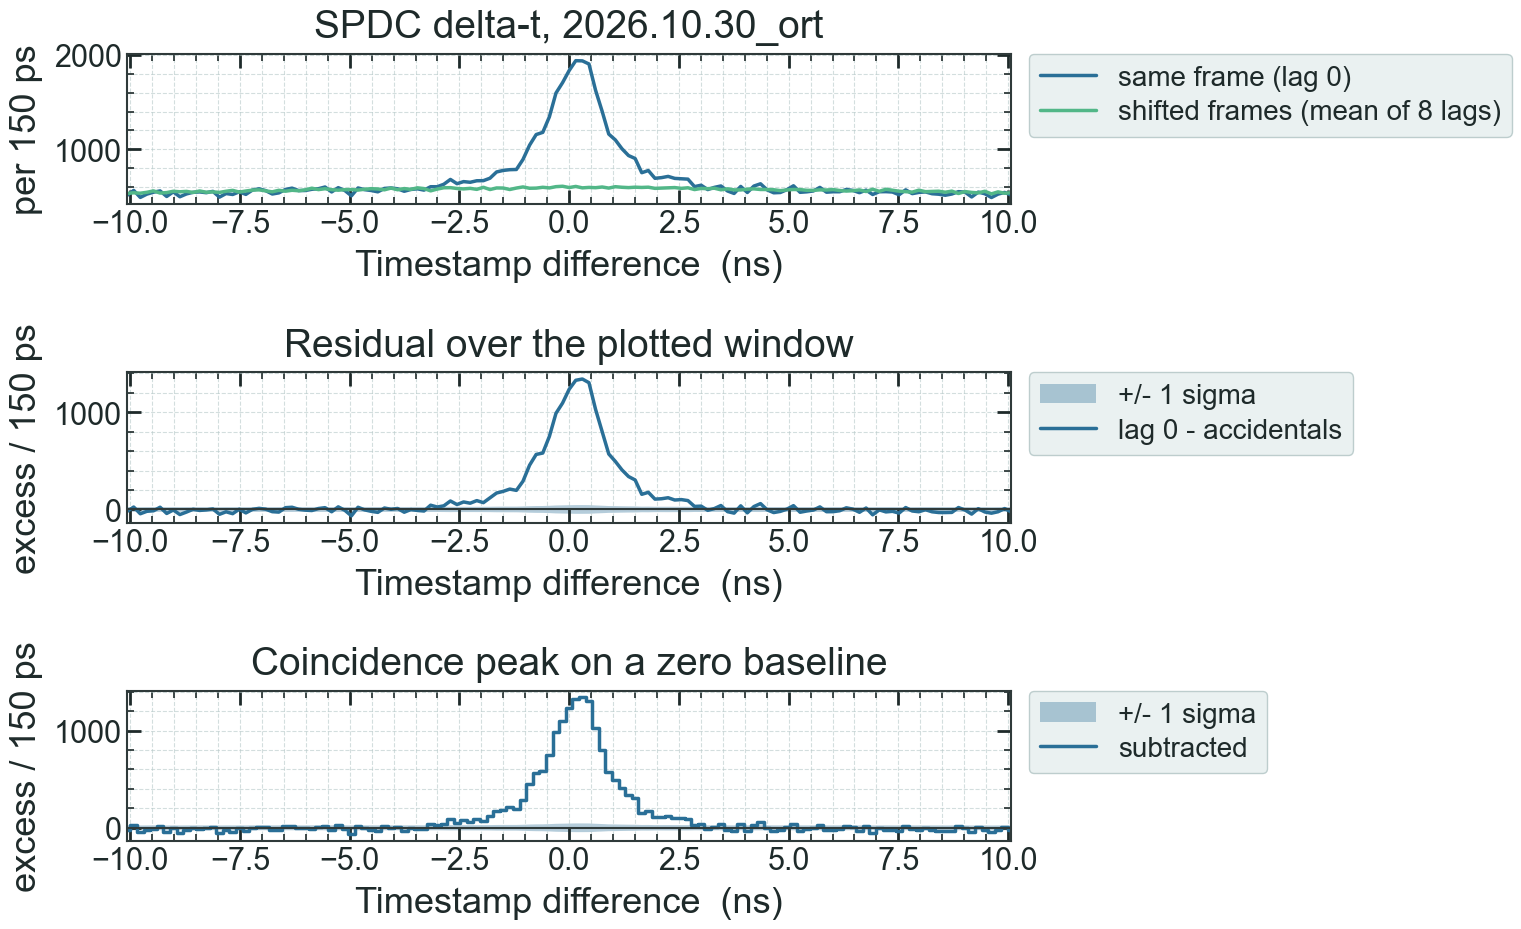

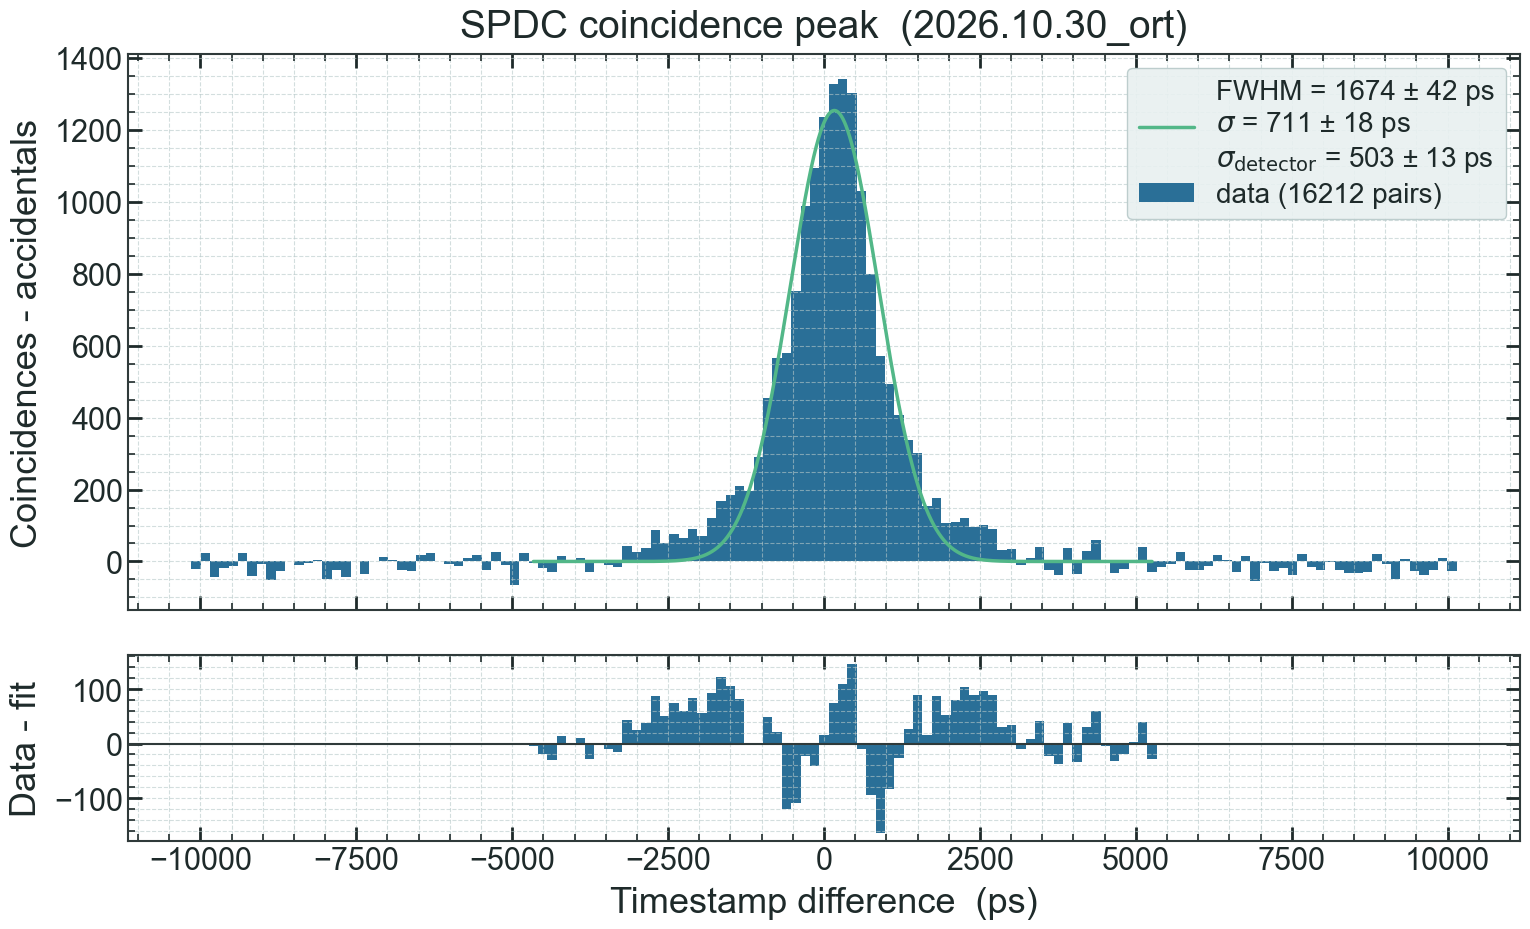

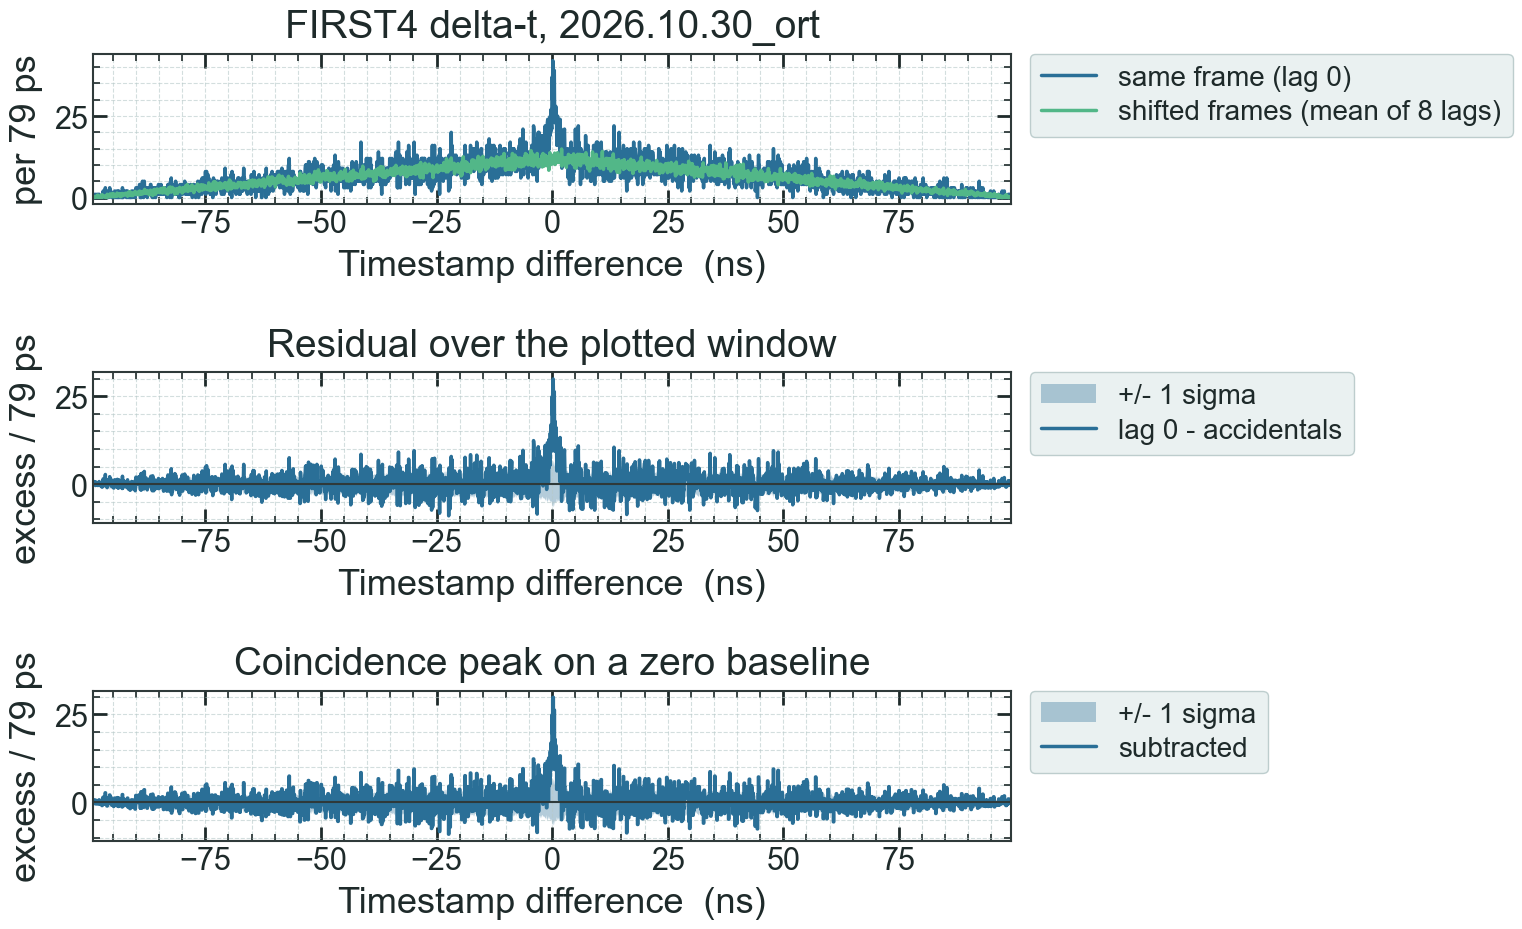

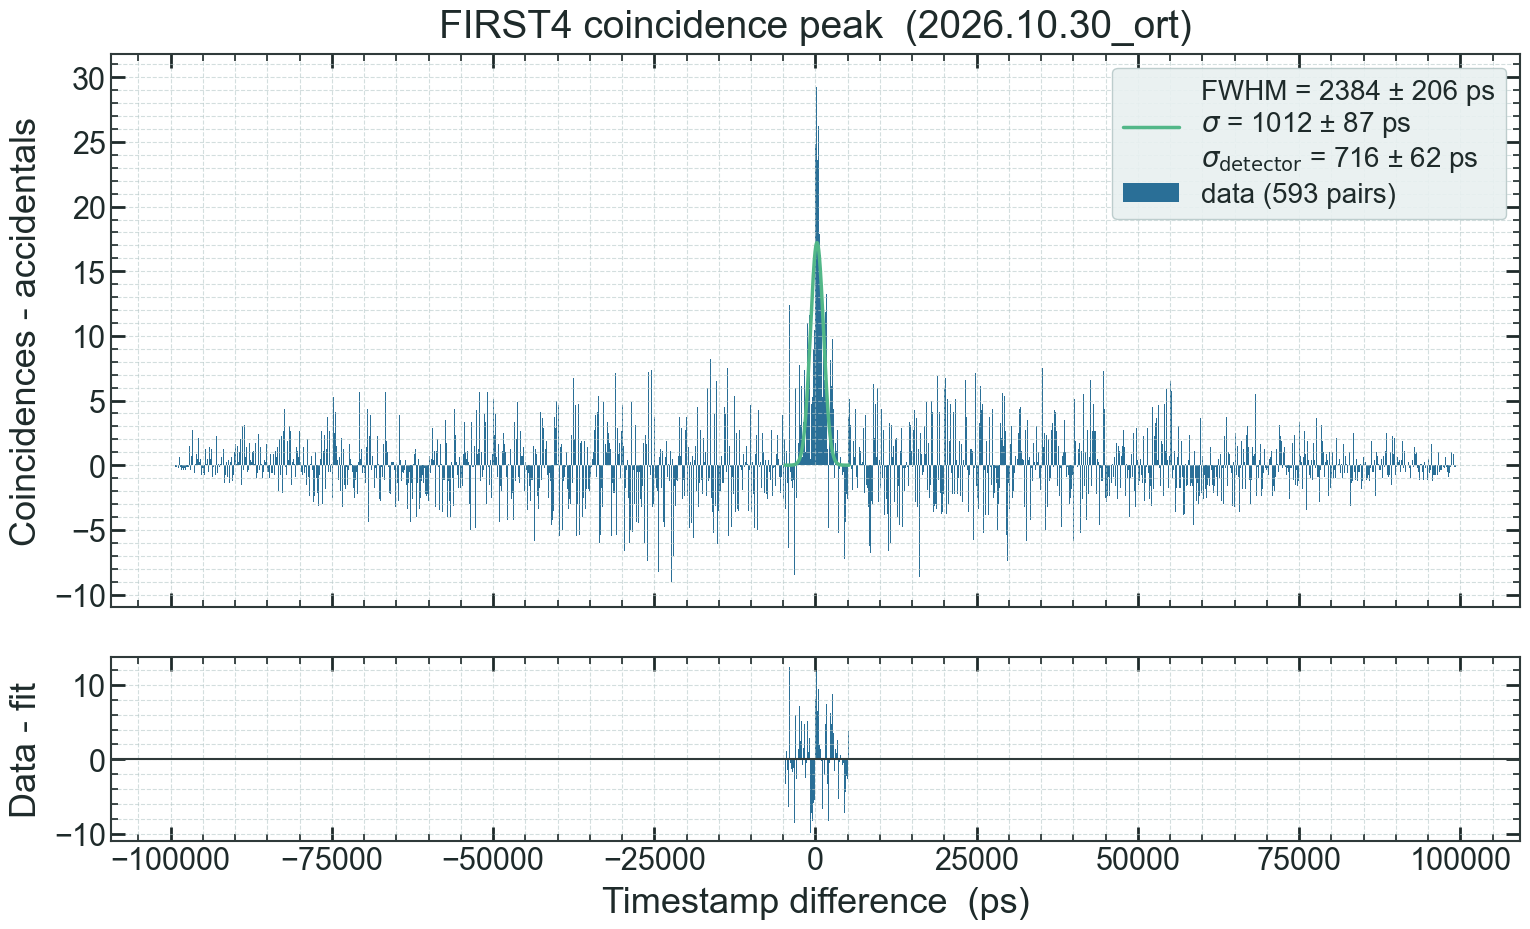

In [7]:
from dapkel.core import store

co.plot_coincidences(
    path, tag, bin_width_s=150e-12, plot_window_s=10e-9, subtract_background=True
)

# only some pixel pairs; labels are "ra,ca-rb,cb"

_, meta = store.load_map(path, kind="coincidences", tag=tag)
print(meta["labels"][:5])
co.plot_coincidences(
    path, tag, pairs=meta["labels"][:4], label="first4", subtract_background=True
)

## 6. Fit your own model

`counts` and `centers` are returned exactly as fitted, so another model needs
nothing from disk. This is useful because a single Gaussian is a poor
description of this sensor: the peak has diffusion tails of about 1 ns on both
sides.

  snapped to the 7.16 ps grid: bin_width 71.58 -> 78.74 ps (11 cells); window 99281 -> 99289 ps.

> > > lag 0 412852 vs accidentals 404051 (mean of 8 shifted lag(s)) over the whole support < < <
  coincidences within +/-5000 ps: 16200 +/- 245  (66.0 sigma), on 39128 accidentals -> CAR 0.414
  control, |delta| beyond the peak: -4608 +/- 504 (-9.1 sigma from zero) - this must be ~0, or the pedestal is not purely accidental.

> > > Plot is saved as 2026.10.30_ort_spdc_background_subtraction.png in D:\Kelpie\2026.10.30\results\coincidences < < <

> > > Plot is saved as 2026.10.30_ort_spdc_coincidences_sub.png in D:\Kelpie\2026.10.30\results\coincidences < < <
  peak: mu 165 ps  FWHM 1671 +- 32 ps  sigma 710 +- 14 ps  sigma_detector 502 +- 10 ps
sigma 322 ± 55 ps, tau+ 578, tau- 628 ps


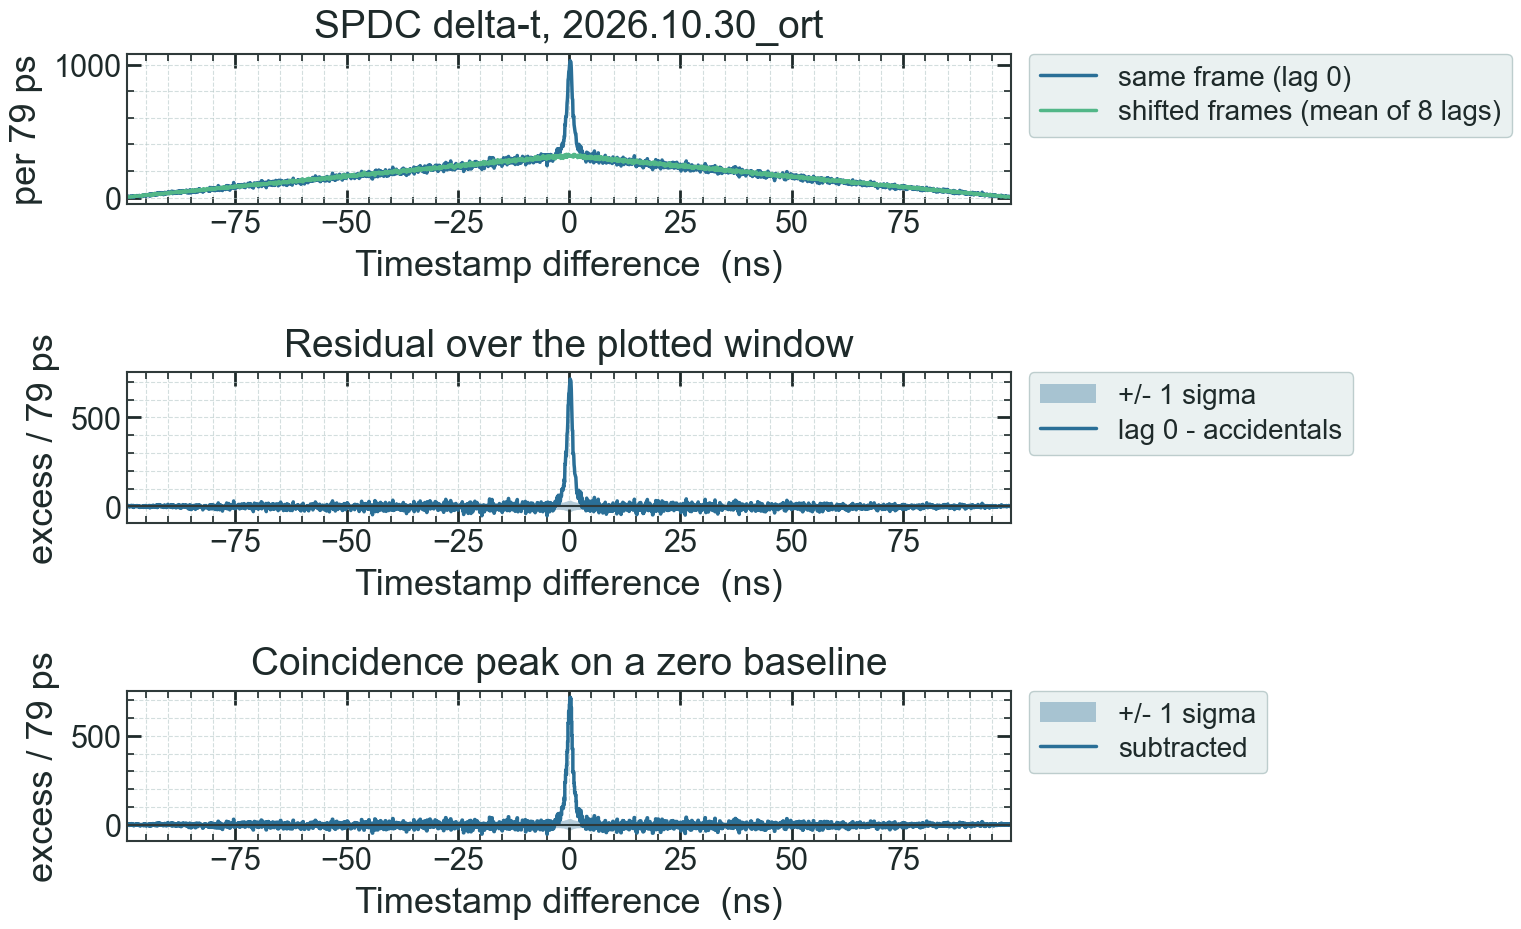

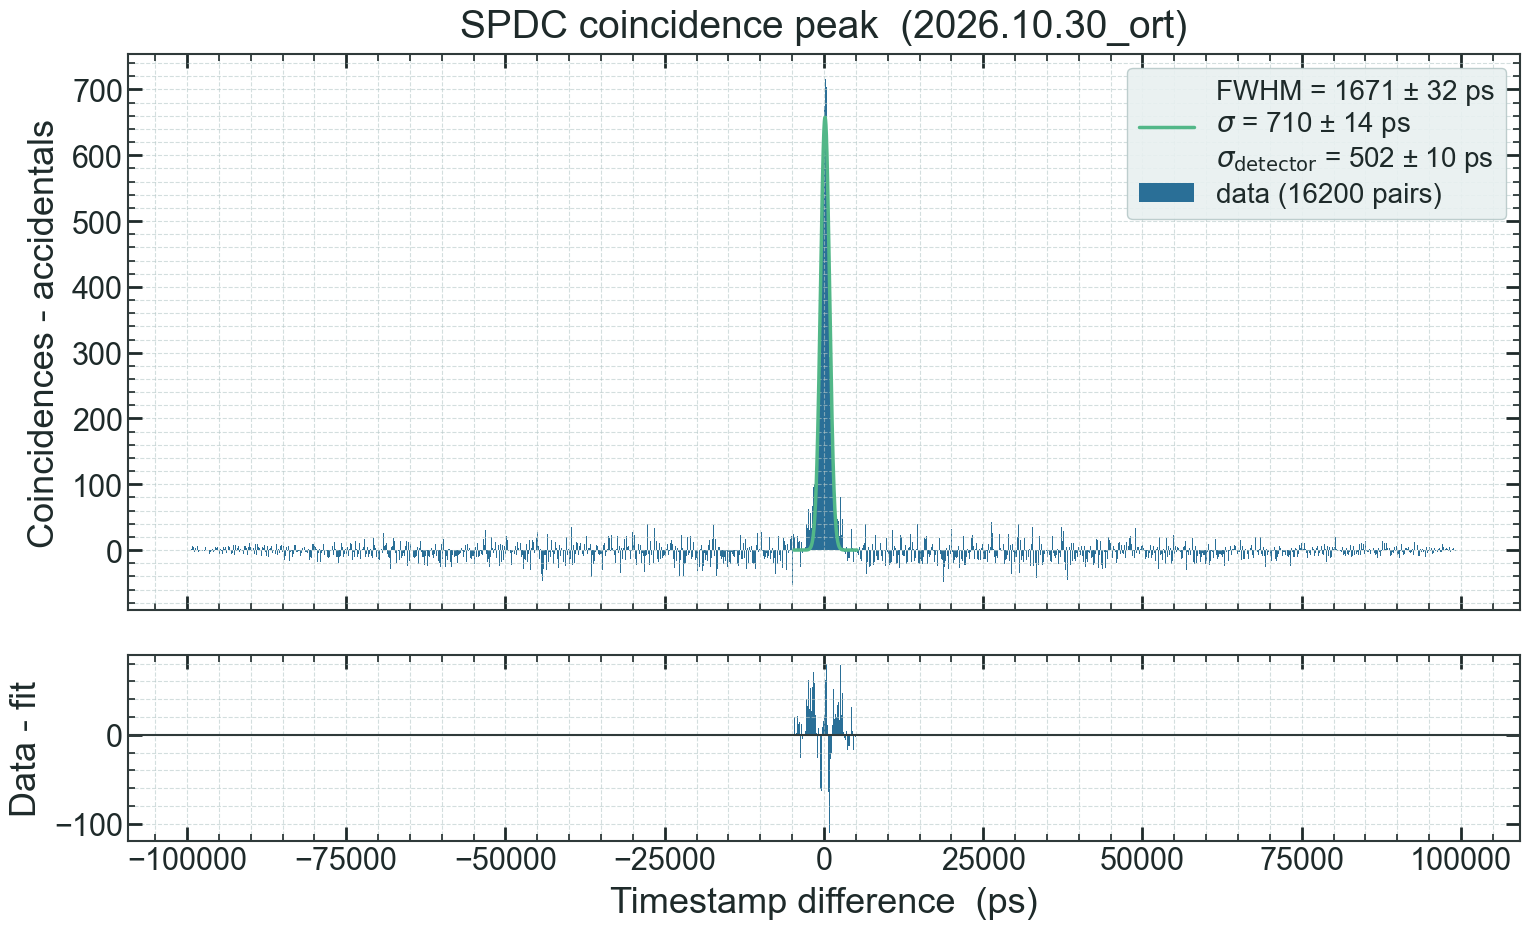

In [8]:
import numpy as np
from scipy.optimize import curve_fit
from scipy.stats import exponnorm

counts, centers, fit = co.plot_coincidences(path, tag, subtract_background=True)
sel = np.abs(centers - fit["mu"]) <= 5000  # ±5 ns, in ps
x, y = centers[sel], counts[sel]
bin_ps = np.median(np.diff(x))


def gauss_two_tails(x, n, mu, sigma, tau_plus, tau_minus):
    """Gaussian convolved with a two-sided exponential: one exGaussian per side."""
    u = x - mu
    w_plus = tau_plus / (tau_plus + tau_minus)
    return (
        n
        * bin_ps
        * (
            w_plus * exponnorm.pdf(u, tau_plus / sigma, scale=sigma)
            + (1 - w_plus) * exponnorm.pdf(-u, tau_minus / sigma, scale=sigma)
        )
    )


popt, pcov = curve_fit(
    gauss_two_tails,
    x,
    y,
    p0=[y.sum(), fit["mu"], 200, 700, 700],
    sigma=np.sqrt(np.abs(y) + 1),
    bounds=([0, -2000, 5, 5, 5], np.inf),
)
err = np.sqrt(np.diag(pcov))
print(
    f"sigma {popt[2]:.0f} ± {err[2]:.0f} ps, tau+ {popt[3]:.0f}, tau- {popt[4]:.0f} ps"
)

## Units and the returned `fit` dict

- **Units:** inputs in seconds; returned centres and fit values in picoseconds.
- **Peak shape:** `amp`, `mu`, `sigma`, `fwhm`, `jitter_per_detector`
  (σ / √2), each with an `_err` entry.
- **Background and range:** `bkg` (0 on the subtracted residual) and
  `fit_range`.
- **Counts:** `car` (raw histogram only) and `n`.
- **`ok`:** False, with a warning, when the fit failed or its σ cannot be told
  from zero.
- **With `subtract_background`, also:** `model_free`, `subtraction` and
  `subtraction_png`.